# Thick Sample Ptychography Forward Model Tutorial 2D

This tutorial demonstrates how to use `thick_ptycho` to set up and solve a 2D forward problem with multiple probes, both iteratively and as a full system.


The forward model solves the paraxial equation:

\begin{equation}
\frac{\partial u}{\partial z} = a \frac{\partial^2 u}{\partial x^2}  + C(x, z) u,
\end{equation}
where
\begin{equation}
a := \frac{1}{2ik} \qquad \text{and} \qquad C(x, z) := \frac{k}{2i} \left(n^2(x, z) - 1\right)
\end{equation}


**$n$ defines the refractive index of the volume. $k$ is the wave number.**

### 1. Import Libraries: Sample Space and Forward Model


In [1]:
from thick_ptycho.simulation.config import SimulationConfig, ProbeType, ProbeConfig
from thick_ptycho.simulation.scan_frame import Limits
from thick_ptycho.simulation.simulation_space import create_simulation_space
from thick_ptycho.simulation.ptycho_object import create_ptycho_object
from thick_ptycho.simulation.ptycho_probe import create_ptycho_probes
from thick_ptycho.forward_model import PWEIterativeLUSolver, MSForwardModelSolver
import os


import time
import numpy as np


from utils import plot_solution, create_random_circle_object, plot_probes, plot_data

### 2. Create Simulated Sample and Space

Choose boundary conditions, probe type, and define the spatial domain and discretization.

In [2]:
probe_config = ProbeConfig(
    type=ProbeType.AIRY_DISK,
    wave_length=6.35e-7,  # meters (0.635 μm). Visible light
    diameter=10e-6,  # [m]
    focus=-5e-6,  # focal length [m]
)
n_medium = 1.0  # Refractive index of surrounding medium

In [3]:
# Width Discretization (Pixels)
scan_points = 1
step_size_px = 500  # Resolution
pad_factor = 1.0  # Must be >= 1.0
# Overlap = N - (scan_points*step_size_px) = padding
# Overlap factor = (N - (scan_points*step_size_px)) / step_size_px
#                = (pad_factor*scan_points) - scan_points) = scan_points*(pad_factor - 1)
# N = int(pad_factor*scan_points*step_size_px)
solve_reduced_domain = True

# Thickness Discretization (Pixels)
nz = 5  # Slices for Multi-Slice


# --- Simulation spatial dimensions (in meters) ---
spatial_limits = Limits(
    x=(0.0, 150e-6),  # Sample width
    z=(0.0, 100e-6),  # Sample thickness
    units="meters",
)

In [4]:
# --- Create the SimulationConfig object ---
# Defines scan path, probe parameters, discretization,
# object domain.
# Solver parameters are defined in the solver classes.
sim_config = SimulationConfig(
    probe_config=probe_config,
    # Spatial discretization
    scan_points=scan_points,
    step_size_px=step_size_px,
    pad_factor=pad_factor,
    solve_reduced_domain=solve_reduced_domain,
    nz=nz,
    spatial_limits=spatial_limits,
    # Refractive index or Transmission Function Constant Surrounding Medium
    medium=n_medium,  # 1.0 for free space
    # Logging and results
    results_dir="./results",
    use_logging=True,
    empty_space_px=0,
)

# --- Create the simulation space ---
simulation_space = create_simulation_space(sim_config)
simulation_space.summarize()
print("Padding/Overlap:", simulation_space.nx - simulation_space.min_nx)

/home/dnz75396/thick_ptycho/thick_ptycho/simulation/config.py:171: RuntimeWarning: solve_reduced_domain=True has no effect when scan_points=1; using full domain.
  warnings.warn(
2026-01-13 11:43:47,686 - INFO - === Scan Summary ===
2026-01-13 11:43:47,687 - INFO -   Sample space (x-range): 1.500e-04 m
2026-01-13 11:43:47,689 - INFO -   Sample space (z-range): 1.000e-04 m
2026-01-13 11:43:47,690 - INFO -   Sample Pixels:          501 px
2026-01-13 11:43:47,693 - INFO -   Step size:              500 px
2026-01-13 11:43:47,695 - INFO -   Number of scan points:  1
2026-01-13 11:43:47,697 - INFO -   Steps in z:             5
2026-01-13 11:43:47,700 - INFO -   Solve reduced domain:   501 px
2026-01-13 11:43:47,701 - INFO -   Probe diameter:         1.000e-05 m
2026-01-13 11:43:47,704 - INFO -   Probe Pixels:           33 px


Padding/Overlap: 1


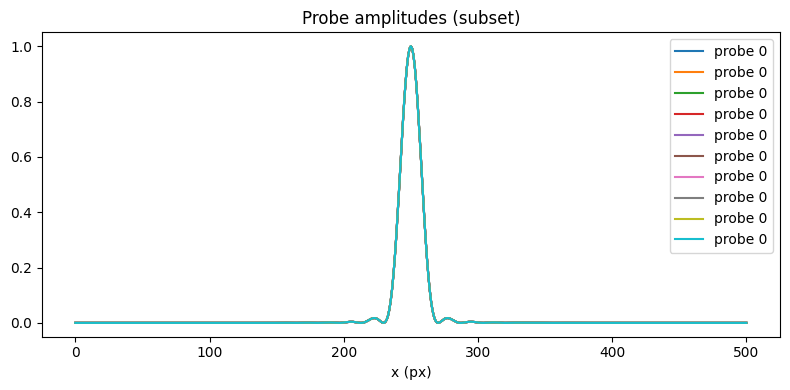

In [5]:
ptycho_object = create_ptycho_object(simulation_space)

# ptycho_object = create_random_circle_object(
#     simulation_space, ptycho_object, num_circles=5
# )


# --- Create a set of Simulated Ptycho Probes (not dependent on number of slices/steps) ---
ptycho_probes = create_ptycho_probes(simulation_space)

plot_probes(simulation_space, ptycho_probes)

method = 'Paraxial'  # 'ASM' or 'Paraxial'
pruning_fraction = 0.0  # Fraction of high frequencies to prune (0.0 to 1.0)
strang_splitting = False  # Use Strang splitting for propagation

### 3. Generate Data with Fine nz Discretization

Solution is a complex propagated field, shape:

(num_projections, num_angles, num_probes, nx[,ny], nz).

In [6]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_ms = MSForwardModelSolver(
    simulation_space, ptycho_probes, method=method, transform='FFT',
    pruning_fraction=pruning_fraction, strang_splitting=strang_splitting
)

# Iterative solution
u_fine, u_final = forward_model_ms.solve(n=ptycho_object.refractive_index)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)


Forward model creation and solving time: 0.00 seconds.



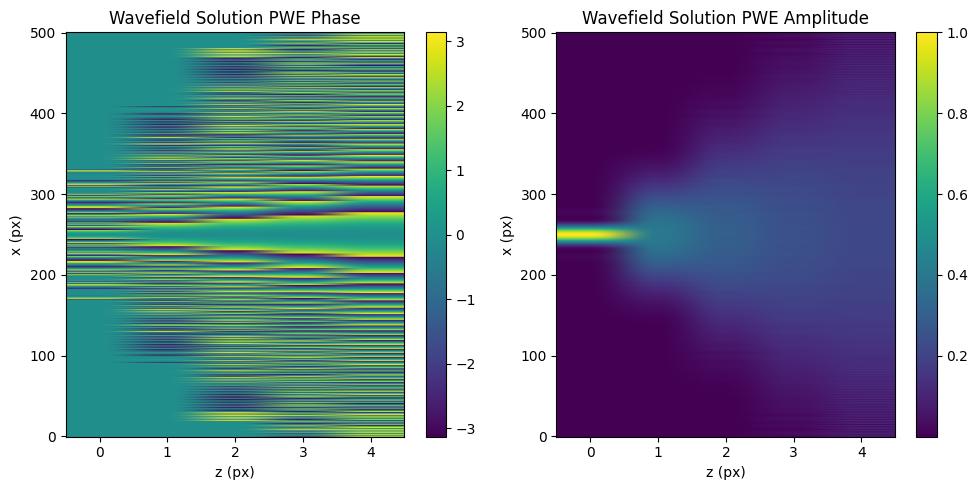

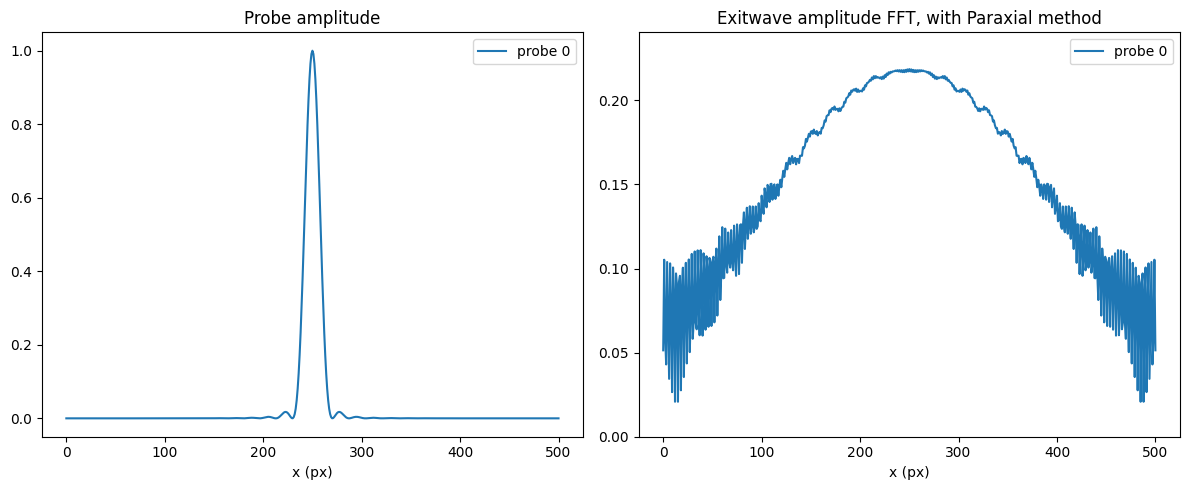

In [7]:
plot_solution(simulation_space, solution=u_fine)
# Plot 1D exit waves
import matplotlib.pyplot as plt
# Plot 1D exit waves#
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Common index for convenience
probe_idx = simulation_space.num_probes // 2
x_vals = range(simulation_space.effective_shape[0])

# --- Subplot 1: Probe ---
axs[0].plot(
    x_vals,
    np.abs(ptycho_probes[0, probe_idx, :]),
    label=f"probe {probe_idx}",
)
axs[0].set_title("Probe amplitude")
axs[0].set_xlabel("x (px)")
axs[0].legend()

# --- Subplot 2: Exitwave ---
axs[1].plot(
    x_vals,
    np.abs(u_final[probe_idx,:]),
    label=f"probe {probe_idx}",
)
axs[1].set_title("Exitwave amplitude FFT, with {} method".format(method))
axs[1].set_xlabel("x (px)")
axs[1].set_ylim(0, np.max(np.abs(u_final[probe_idx,:]))*1.1)
axs[1].legend()

plt.tight_layout()
plt.show()

In [8]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_ms = MSForwardModelSolver(
    simulation_space, ptycho_probes, method=method, transform='DST',
    pruning_fraction=pruning_fraction,
    strang_splitting=strang_splitting
)


# Iterative solution
u_fine, u_final = forward_model_ms.solve(n=ptycho_object.refractive_index)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)

Forward model creation and solving time: 0.00 seconds.



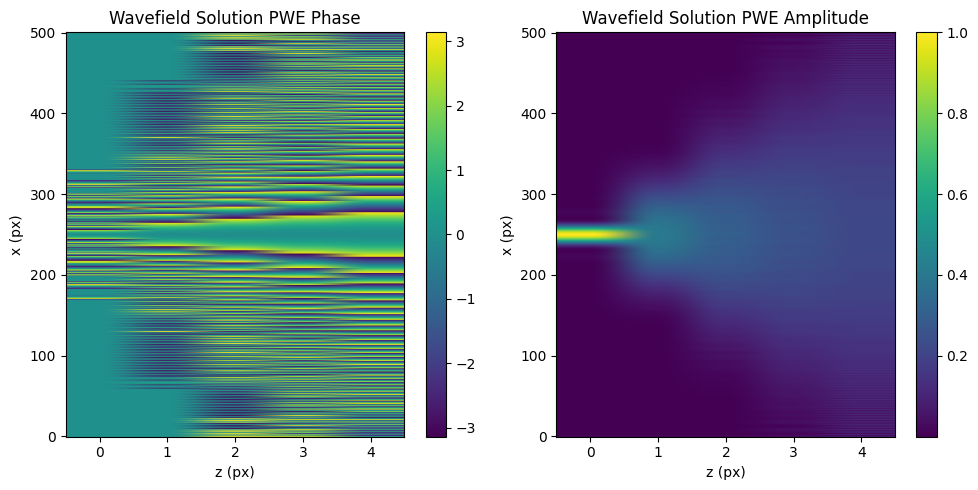

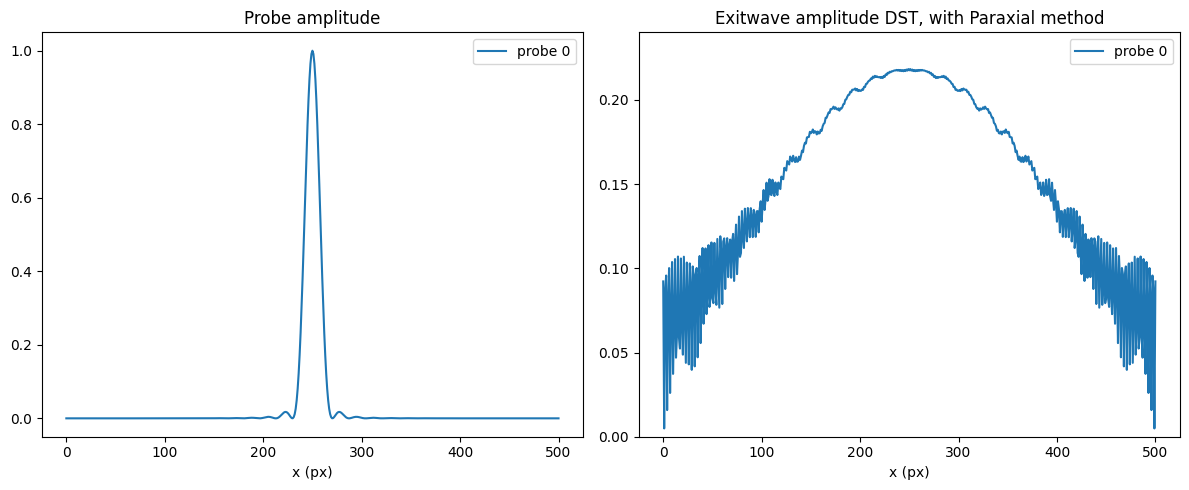

In [9]:
plot_solution(simulation_space, solution=u_fine)
# Plot 1D exit waves
import matplotlib.pyplot as plt
# Plot 1D exit waves#
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Common index for convenience
probe_idx = simulation_space.num_probes // 2
x_vals = range(simulation_space.effective_shape[0])

# --- Subplot 1: Probe ---
axs[0].plot(
    x_vals,
    np.abs(ptycho_probes[0, probe_idx, :]),
    label=f"probe {probe_idx}",
)
axs[0].set_title("Probe amplitude")
axs[0].set_xlabel("x (px)")
axs[0].legend()

# --- Subplot 2: Exitwave ---
axs[1].plot(
    x_vals,
    np.abs(u_final[probe_idx,:]),
    label=f"probe {probe_idx}",
)
axs[1].set_title("Exitwave amplitude DST, with {} method".format(method))
axs[1].set_xlabel("x (px)")
axs[1].set_ylim(0, np.max(np.abs(u_final[probe_idx,:]))*1.1)
axs[1].legend()

plt.tight_layout()
plt.show()

In [10]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_ms = MSForwardModelSolver(
    simulation_space, ptycho_probes, method=method, transform='DCT',
    pruning_fraction=pruning_fraction, strang_splitting=strang_splitting
)

# Iterative solution
u_fine, u_final = forward_model_ms.solve(n=ptycho_object.refractive_index)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)

Forward model creation and solving time: 0.00 seconds.



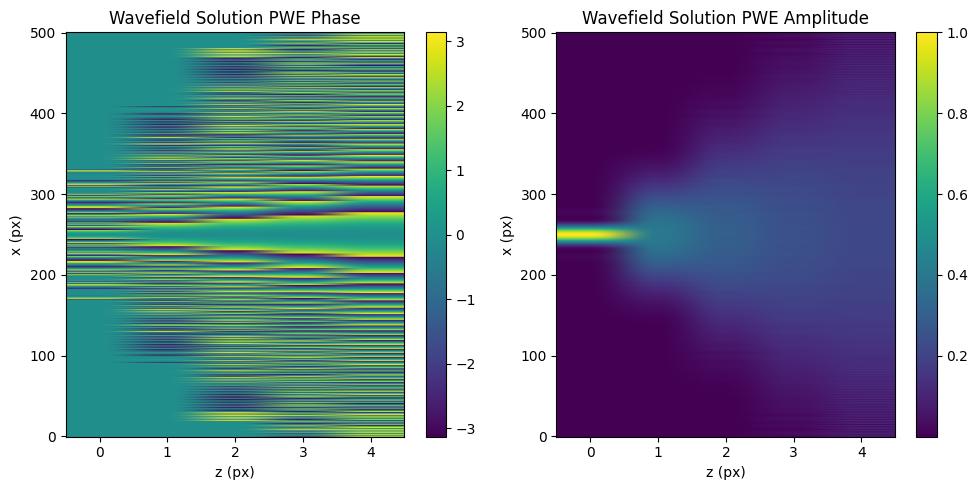

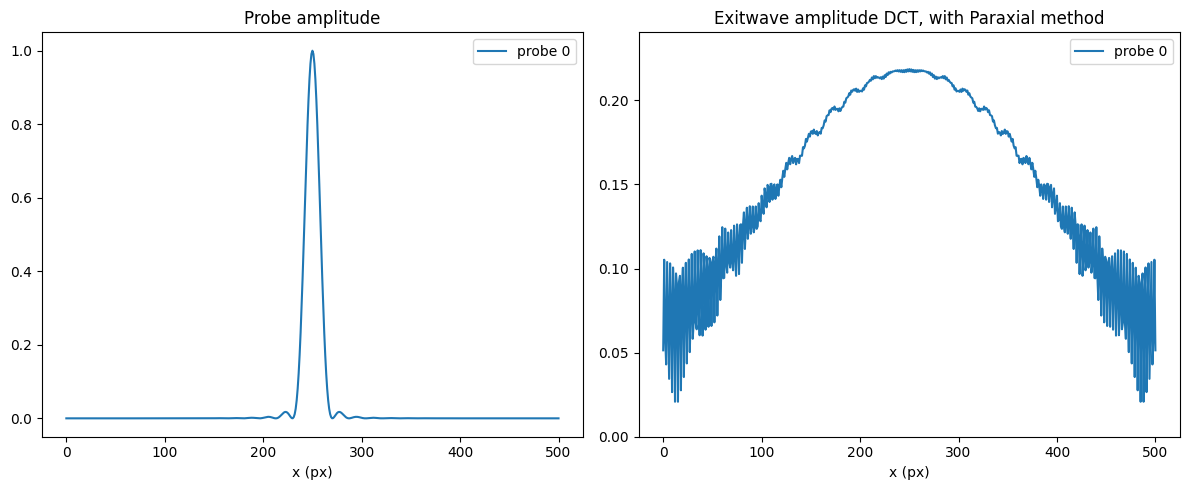

In [11]:
plot_solution(simulation_space, solution=u_fine)
# Plot 1D exit waves
import matplotlib.pyplot as plt
# Plot 1D exit waves#
# Plot 1D exit waves#
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Common index for convenience
probe_idx = simulation_space.num_probes // 2
x_vals = range(simulation_space.effective_shape[0])

# --- Subplot 1: Probe ---
axs[0].plot(
    x_vals,
    np.abs(ptycho_probes[0, probe_idx, :]),
    label=f"probe {probe_idx}",
)
axs[0].set_title("Probe amplitude")
axs[0].set_xlabel("x (px)")
axs[0].legend()

# --- Subplot 2: Exitwave ---
axs[1].plot(
    x_vals,
    np.abs(u_final[probe_idx,:]),
    label=f"probe {probe_idx}",
)
axs[1].set_title("Exitwave amplitude DCT, with {} method".format(method))
axs[1].set_xlabel("x (px)")
axs[1].set_ylim(0, np.max(np.abs(u_final[probe_idx,:]))*1.1)
axs[1].legend()

plt.tight_layout()
plt.show()

In [12]:
# Solve Full Space Space, Iterative
# --- Create Forward Model ---
time_start = time.time()
forward_model_ms = MSForwardModelSolver(
    simulation_space, ptycho_probes, method=method, transform='absorbing_boundary',
    pruning_fraction=pruning_fraction, strang_splitting=strang_splitting
)

# Iterative solution
u_fine, u_final = forward_model_ms.solve(n=ptycho_object.refractive_index)
time_end = time.time()
print(
    f"Forward model creation and solving time: {time_end - time_start:.2f} seconds.\n"
)


Forward model creation and solving time: 0.01 seconds.



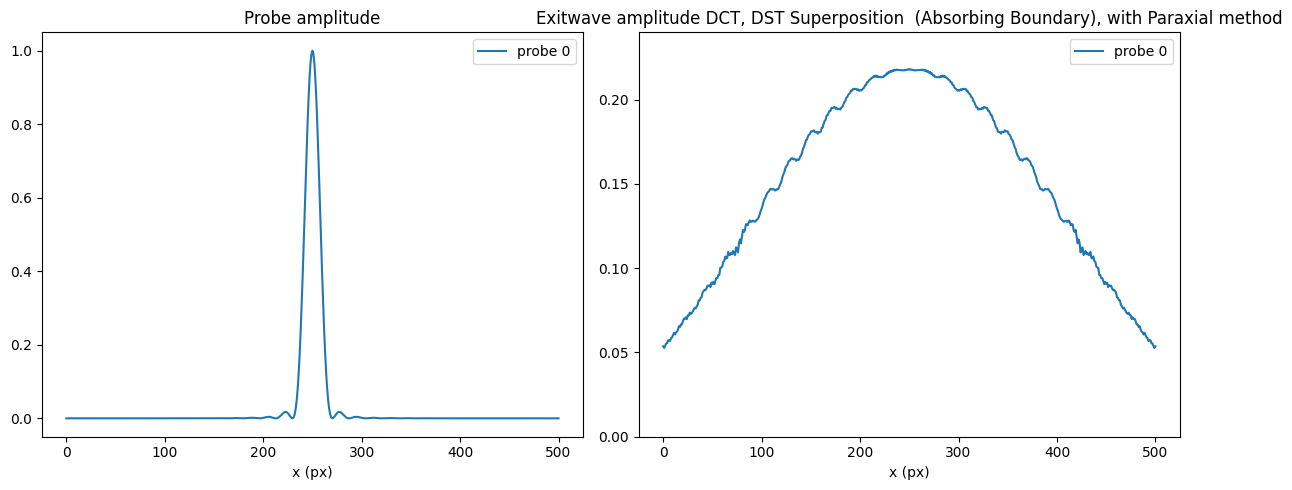

In [13]:
# plot_solution(simulation_space, solution=u_fine)
# Plot 1D exit waves
import matplotlib.pyplot as plt
# Plot 1D exit waves#
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Common index for convenience
probe_idx = simulation_space.num_probes // 2
x_vals = range(simulation_space.effective_shape[0])

# --- Subplot 1: Probe ---
axs[0].plot(
    x_vals,
    np.abs(ptycho_probes[0, probe_idx, :]),
    label=f"probe {probe_idx}",
)
axs[0].set_title("Probe amplitude")
axs[0].set_xlabel("x (px)")
axs[0].legend()

# --- Subplot 2: Exitwave ---
axs[1].plot(
    x_vals,
    np.abs(u_final[probe_idx,:]),
    label=f"probe {probe_idx}",
)
axs[1].set_title("Exitwave amplitude DCT, DST Superposition  (Absorbing Boundary), with {} method".format(method))
axs[1].set_xlabel("x (px)")
axs[1].set_ylim(0, np.max(np.abs(u_final[probe_idx,:]))*1.1)
axs[1].legend()

plt.tight_layout()
plt.show()